# Author matching (B.6)

Inputs: `results/matching/` (B.6), `results/groundtruth/authors/` (A.1). Plots: `plots/<variant>/matching_*`. Titles only in PNG.

In [1]:
# Setup: code/libs importable, library changes re-imported automatically
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path
PROJECT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'code' / 'libs').exists())
sys.path.insert(0, str(PROJECT / 'code' / 'libs'))

import json
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from matching import stats
from utils import constants as cons
from viz import constants as viscons
from viz.figures import save_figure
from viz.labels import model_labels
from viz.style import apply_style

apply_style()

'DejaVu Serif'

In [2]:
# Parameters
SMOKE = False                                   # True: smoke-test outputs in tmp/smoke/, False: results/
VARIANT = 'main'                               # analysis variant: config/variants/<VARIANT>.yaml (main: config/analysis.yaml)
MODELS = None                                  # None = all models
SAVE = False
N_EXAMPLES = 10
RESULTS_DIR = PROJECT / 'tmp' / 'smoke' if SMOKE else Path(cons.DEFAULT_RESULTS_DIR)
from utils import analysis_config
V = analysis_config.notebook_variant(VARIANT, SMOKE)  # folders + config of the variant (configure_variant.py)

In [3]:
# Data: one row per recommendation, the B.6b thresholds, the candidates and the OpenAlex display names
MATCH_DIR = Path(V['matching_dir'])           # the variant's own B.6b, or main's
CANDIDATES = RESULTS_DIR / 'matching' / 'candidates'
PLOTS_DIR = Path(V['plots_dir'])
if not (MATCH_DIR / '_params.json').exists():
    raise FileNotFoundError(f"No B.6b output in {MATCH_DIR}: run run_matching_pipeline.sh (-r {RESULTS_DIR}), or check SMOKE / VARIANT")
params = json.loads((MATCH_DIR / '_params.json').read_text())
df = stats.load_matches(MATCH_DIR, MODELS)
df['rule'], df['outcome'] = stats.rule(df), stats.outcome(df)
labels = {**model_labels(df[cons.COL_MODEL].unique()), 'all models': 'all models'}
print(params)
print(f"{df[cons.COL_MODEL].nunique()} models | {len(df):,} recommendations | {df['rec_name'].notna().mean():.1%} with a name")

{'seed': 42, 'jw_full': 0.9, 'jw_first': 0.9, 'jw_last': 0.9, 'min_field_share': 0.0, 'seniority_definition': 'three', 'reference_year': 2025, 'junior_max': 10, 'senior_min': 20, 'single_cutoff': 10}
43 models | 3,869,884 recommendations | 97.6% with a name


In [4]:
# Helper: stacked horizontal bars, one row per model (+ 'all models' at the bottom)
def stacked_bars(table, colors, xlabel, title, name):
    table = table.rename(index=labels)
    fig, ax = plt.subplots(figsize=(viscons.PAPER_TEXT_WIDTH_IN, 0.6 + 0.16 * len(table)))
    left = np.zeros(len(table))
    for column, color in zip(table.columns, colors):
        ax.barh(table.index, table[column] * 100, left=left, color=color, edgecolor=viscons.COLOR_BAR_EDGE,
                linewidth=0.3, label=column)
        left += table[column].to_numpy() * 100
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    ax.legend(ncol=len(table.columns), loc='lower center', bbox_to_anchor=(0.5, 1.0 + 1.2 / len(table)), fontsize='x-small')
    if SAVE:
        save_figure(fig, name, PLOTS_DIR)
    return fig

## 1. Matching rule

rule,exact_display,exact_alternative,short,initials,fuzzy,no match,no name
model,,,,,,,
all models,0.731,0.015,0.086,0.001,0.028,0.11,0.028


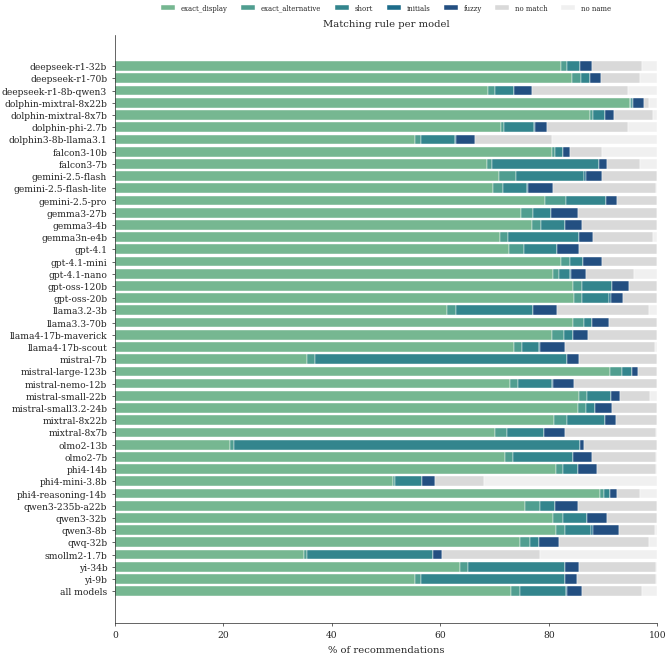

In [5]:
# Share of recommendations by the rule that decided (strictest rule with a match)
rule_shares = stats.shares(df, df['rule'], stats.RULE_ORDER)
colors = sns.color_palette('crest', len(cons.MATCH_RULES)) + ['#d9d9d9', '#f0f0f0']
stacked_bars(rule_shares, colors, '% of recommendations', 'Matching rule per model', 'matching_rules');
rule_shares.loc[['all models']].round(3)

## 2. Matching levels

,matched_name,matched_name_field,matched_name_seniority,matched_author
model,,,,
all models,0.886,0.602,0.756,0.416


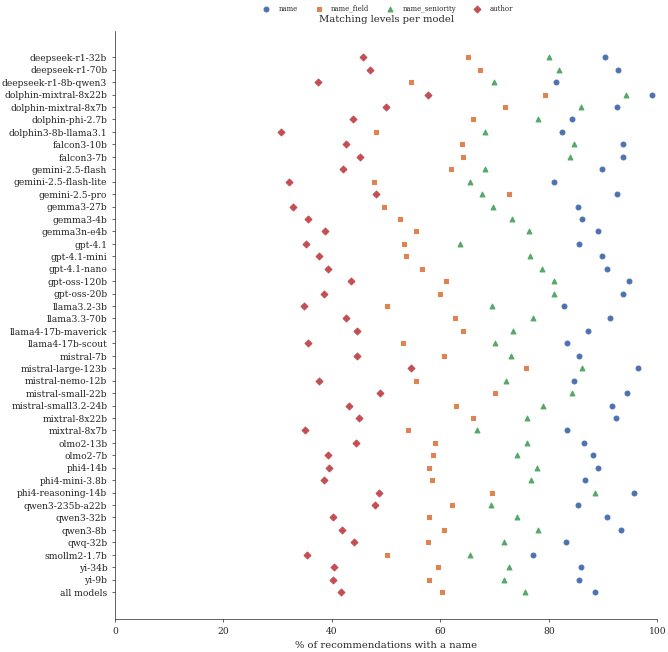

In [6]:
# Share of named recommendations matched at each level, per model
rates = stats.level_rates(df).rename(index=labels)
fig, ax = plt.subplots(figsize=(viscons.PAPER_TEXT_WIDTH_IN, 0.6 + 0.16 * len(rates)))
for level, marker in zip(stats.LEVELS, ['o', 's', '^', 'D']):
    ax.scatter(rates[level] * 100, rates.index, s=12, marker=marker, label=level.replace('matched_', ''))
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel('% of recommendations with a name')
ax.set_title('Matching levels per model')
ax.legend(ncol=4, loc='lower center', bbox_to_anchor=(0.5, 1.02), fontsize='x-small')
if SAVE:
    save_figure(fig, 'matching_levels', PLOTS_DIR)
rates.loc[['all models']].round(3)

## 3. Author outcome

outcome,author,field only,seniority only,ambiguous,name only,no match,no name
model,,,,,,,
all models,0.405,0.041,0.19,0.14,0.086,0.11,0.028


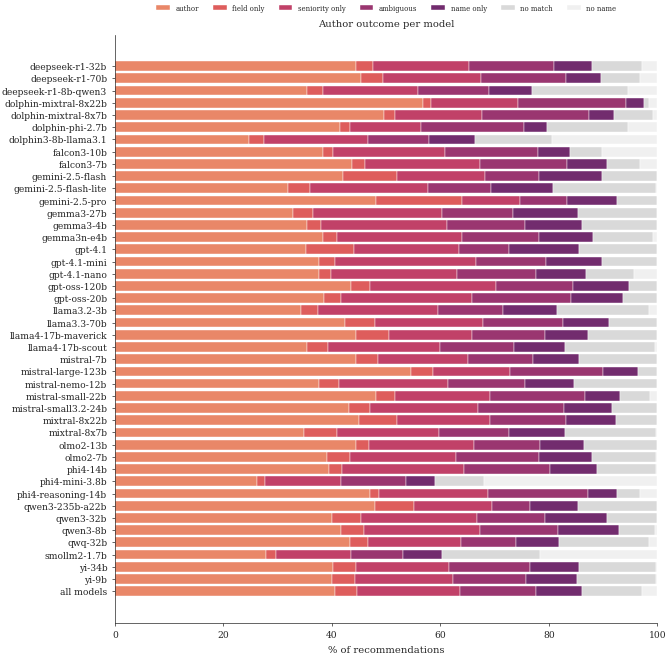

In [7]:
# Author (all 3 conditions) vs partial (field only / seniority only) vs ambiguous / name only / no match
outcome_shares = stats.shares(df, df['outcome'], stats.OUTCOME_ORDER)
colors = sns.color_palette('flare', 5) + ['#d9d9d9', '#f0f0f0']
stacked_bars(outcome_shares, colors, '% of recommendations', 'Author outcome per model', 'matching_outcomes');
outcome_shares.loc[['all models']].round(3)

## 4. Homonyms

author-level matches with > 1 person (random pick decides): 53.8%


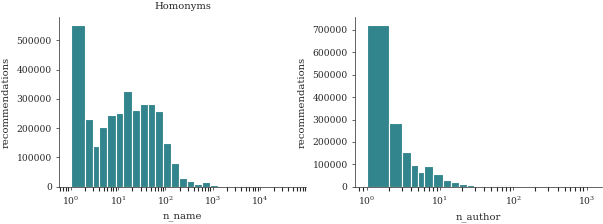

In [8]:
# Candidates per matched recommendation (n_name) and among the author-level people (n_author)
fig, axes = plt.subplots(1, 2, figsize=(viscons.PAPER_TEXT_WIDTH_IN, 2.2))
for ax, column in zip(axes, ['n_name', 'n_author']):
    values = df.loc[df[column] > 0, column]
    bins = np.unique(np.logspace(0, np.log10(max(values.max(), 2)), 30).astype(int))
    ax.hist(values, bins=bins, color=sns.color_palette('crest', 1)[0])
    ax.set_xscale('log')
    ax.set_xlabel(column)
    ax.set_ylabel('recommendations')
axes[0].set_title('Homonyms')
if SAVE:
    save_figure(fig, 'matching_homonyms', PLOTS_DIR)
print(f"author-level matches with > 1 person (random pick decides): {(df.loc[df.n_author > 0, 'n_author'] > 1).mean():.1%}")

## 5. Rules decided and overlap

In [9]:
# Per decided rule: recommendations, and median candidates of every rule
stats.tier_overlap(df)

,n_recommendations,n_rule_exact_display,n_rule_exact_alternative,n_rule_short,n_rule_initials,n_rule_fuzzy
match_rule,,,,,,
exact_display,2844026,14.0,2.0,33.0,0.0,0.0
exact_alternative,62285,0.0,1.0,2.0,0.0,0.0
short,333060,0.0,0.0,25.0,0.0,0.0
initials,2033,0.0,0.0,0.0,19.0,0.0
fuzzy,111462,0.0,0.0,0.0,0.0,2.0


## 6. Fuzzy scores

477,342 recommendations scored by the fuzzy rule | 23.4% matched


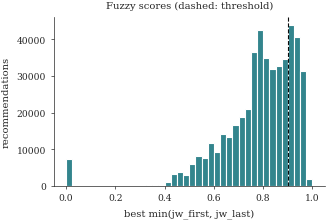

In [10]:
# Best fuzzy score of names without a stricter match: min(jw_first, jw_last), with the B.6b threshold
fuzzy = df[df['rule'].isin([cons.MATCH_FUZZY, stats.NO_MATCH]) & df['jw_parts_max'].notna()]
threshold = min(params['jw_first'] or 0, params['jw_last'] or 0)
fig, ax = plt.subplots(figsize=(viscons.PAPER_TEXT_WIDTH_IN / 2, 2.2))
ax.hist(fuzzy['jw_parts_max'], bins=np.linspace(0, 1, 41), color=sns.color_palette('crest', 1)[0])
ax.axvline(threshold, color=viscons.COLOR_ERROR_BAR, linewidth=0.8, linestyle='--')
ax.set_xlabel('best min(jw_first, jw_last)')
ax.set_ylabel('recommendations')
ax.set_title('Fuzzy scores (dashed: threshold)')
if SAVE:
    save_figure(fig, 'matching_fuzzy_scores', PLOTS_DIR, FORMATS)
print(f"{len(fuzzy):,} recommendations scored by the fuzzy rule | {(fuzzy['rule'] == cons.MATCH_FUZZY).mean():.1%} matched")

In [11]:
# Examples around the threshold: recommended name vs the OpenAlex name that was scored (B.6a candidates)
near = duckdb.sql(f"""
    SELECT c.rec_name, c.jw_name, a.display_name, round(c.jw_full, 3) AS jw_full, round(c.jw_first, 3) AS jw_first,
           round(c.jw_last, 3) AS jw_last, round(c.edit_first, 3) AS edit_first, c.jw_flipped
    FROM read_parquet('{CANDIDATES}/bucket-*.parquet') c
    LEFT JOIN read_parquet('{RESULTS_DIR}/groundtruth/authors/bucket-*.parquet') a USING (author_id)
    WHERE least(c.jw_first, c.jw_last) BETWEEN {threshold - 0.05} AND {threshold + 0.05}
      AND NOT (c.exact_display OR c.exact_alternative OR c.short OR c.initials)
    ORDER BY random() LIMIT {N_EXAMPLES}""").df()
near.assign(parts=near[['jw_first', 'jw_last']].min(axis=1)).sort_values('parts')

,rec_name,jw_name,display_name,jw_full,jw_first,jw_last,edit_first,jw_flipped,parts
4,lilibeth|suarez,lisbet suarez,Lisbet D. Suarez,0.926,0.856,1.000,0.375,False,0.856
0,riana|parker,brian parker,BRian Parker,0.914,0.867,1.000,0.400,False,0.867
5,simiso|zhou,zhou sis,None,0.945,0.867,1.000,0.500,True,0.867
7,yara|chen,ya chen,None,0.941,0.867,1.000,0.500,False,0.867
8,migueli|torres,miguel torres rodriguez,Miguel Torres Rodriguez,0.899,0.971,0.875,0.143,False,0.875
6,elenaamiento|navarro,elena navarro rodriguez,Elena NAVARRO RODRÍGUEZ,0.833,0.883,0.882,0.583,False,0.882
1,jeannette|lorenz,jeanette miriam lorenz,Jeanette Miriam Lorenz,0.911,0.884,1.000,0.533,False,0.884
9,luisita|rodriguez,luis matilla rodriguez,Luis Matilla Rodríguez,0.931,0.888,1.000,0.500,False,0.888
3,kimio|yanagisawa,kiminori yanagisawa,Kiminori Yanagisawa,0.931,0.925,1.000,0.375,False,0.925
2,yoshinori|tsuchida,yoshio tsuchida,Yoshio TSUCHIDA,0.927,0.933,1.000,0.333,False,0.933


## 7. Initials

In [12]:
# Initials-only names ('J. Smith'): candidates per recommendation and the largest blocks
initials = df[df['rule'] == cons.MATCH_INITIALS]
print(f"{len(initials):,} recommendations matched by initials | median candidates {initials['n_name'].median():.0f}")
initials.groupby(['first_name', 'last_name'])['n_name'].max().sort_values(ascending=False).head(N_EXAMPLES)

2,033 recommendations matched by initials | median candidates 19


first_name  last_name
Z S K       Zhang        54691
S D M M P   Singh        18932
S P K       A            16341
A A J R M   S            12016
J P E       Smith        11903
J A M B     Smith        11903
S D G       Khan         11122
A G K       Ahmed        10634
M.L.R       Martin        9344
P K J       M             9311
Name: n_name, dtype: int64

## 8. Examples

In [13]:
# Random author-level matches next to the OpenAlex display name of the picked person
picked = df[df['matched_author']].sample(min(N_EXAMPLES, int(df['matched_author'].sum())), random_state=cons.DEFAULT_SEED)
names = duckdb.sql(f"""SELECT author_id, display_name, first_pub_year FROM read_parquet('{RESULTS_DIR}/groundtruth/authors/bucket-*.parquet')
                      WHERE author_id IN ({', '.join(map(str, picked['author_id'].astype('int64'))) or 'NULL'})""").df()
picked[[cons.COL_MODEL, 'field', 'seniority', 'first_name', 'last_name', 'match_rule', 'n_name', 'n_author', 'author_id']] \
    .merge(names, on='author_id', how='left')

,model,field,seniority,first_name,last_name,match_rule,n_name,n_author,author_id,display_name,first_pub_year
0,phi4-14b-q4_K_M,Psychology,senior,Masaru,Oda,exact_display,11,3,5149664291,Masaru Oda,1997
1,dolphin-phi-2_7b-v2_6-q4_K_M,Physics,senior,John,Doe,exact_display,79,1,5109346276,John Doe,1901
2,mistral-small-22b-instruct-2409-q4_K_M,Physics,senior,David,Hestenes,exact_display,2,1,5050440211,David Hestenes,1963
3,gpt-4_1-2025-04-14,Mathematics,senior,Pietro,Corvaja,exact_display,2,1,5060602998,Pietro Corvaja,1995
4,gemma3-27b-it-q4_K_M,Sociology,senior,Sharlene,Swartz,exact_display,1,1,5088462197,Sharlene Swartz,1991
5,deepseek-r1-32b-qwen-distill-q4_K_M,Sociology,junior,Jane,Doe,exact_display,48,1,5028686338,Doe Jane,2020
6,deepseek-r1-70b-llama-distill-q4_K_M,Physics,senior,Yoshinori,Tokura,exact_display,56,7,5131040984,Yoshinori Tokura,2000
7,olmo2-13b-1124-instruct-q4_K_M,Sociology,senior,John Doe,Johnson,short,258,47,5084306719,John T. Johnson,1967
8,gpt-oss-120b,Physics,senior,Andrew J,Mackenzie,short,56,4,5014554410,Andrew Peter Mackenzie,1960
9,llama4-17b-maverick-128e-instruct-q4_K_M,Computer Science,senior,Ana,Pérez,exact_display,33,2,5047686621,Ana Pérez,1999
